In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append('..')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from config import get_device, WAV_INPUT_DIR, WHISPER_TRANSCRIPTS_DIR
from whisper_transcripts import get_transcript
from items import WhisperTranscript

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



In [3]:
TO_TRANSCRIBE = list(WAV_INPUT_DIR.iterdir())
print(len(TO_TRANSCRIBE))
TO_TRANSCRIBE

9


[PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch7-9.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch15-19.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch10-12.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch23-25.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch1-3.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch4-6.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch26-27.wav'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/a

In [4]:
WAV = TO_TRANSCRIBE[0]
WAV

PosixPath('/mnt/sda/data-output/phd/Pallier2025/listen/ds007523-download/sourcedata/stimuli/audio/ch20-22.wav')

### Transcribe

In [5]:
# device = get_device()
# device

In [6]:
# res = get_transcript(
#     audio=str(WAV),
#     model_size="large-v2",
#     device=device,
#     initial_prompt=None,
#     fp16=False,
#     language="fr",
#     do_vad=False,
# )

### Load result

In [7]:
ready_files = list(WHISPER_TRANSCRIPTS_DIR.iterdir())
print(len(ready_files))
ready_files

18


[PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch10-12_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch13-14_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch7-9_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch26-27_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch4-6_whisper_base.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch23-25_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch4-6_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch1-3_whisper_large-v2.json'),
 PosixPath('/mnt/sda/data-output/phd/Pallier2025_results/whisper_transcripts/ch20-22_whisper_base.json'),
 PosixPath('/mnt/sda/data-outp

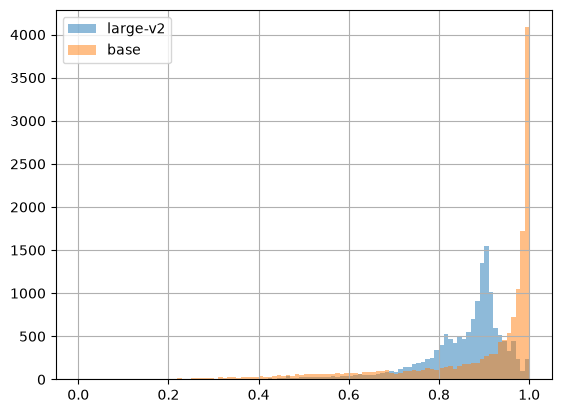

In [8]:
size = 'large-v2'
df_large = []
for rf in ready_files:
    wav_name = rf.stem
    if not wav_name.endswith(size):
        continue
    wav_name = wav_name.split("_whisper_")[0]
    res = WhisperTranscript.from_wav_path(wav_name, size)
    for s in res.whisper_result['segments']:
        for w in s['words']:
            w['file'] = wav_name
            df_large.append(w)
df_large = pd.DataFrame(df_large)

size = 'base'
df_base = []
for rf in ready_files:
    wav_name = rf.stem
    if not wav_name.endswith(size):
        continue
    wav_name = wav_name.split("_whisper_")[0]
    res = WhisperTranscript.from_wav_path(wav_name, size)
    for s in res.whisper_result['segments']:
        for w in s['words']:
            w['file'] = wav_name
            df_base.append(w)
df_base = pd.DataFrame(df_base)

df_large.confidence.hist(bins=np.arange(0, 1.01, 0.01), alpha=0.5, label='large-v2')
df_base.confidence.hist(bins=np.arange(0, 1.01, 0.01), alpha=0.5, label='base')
plt.legend()

In [9]:
df_large.confidence.median(), df_base.confidence.median()

(np.float64(0.883), np.float64(0.962))

In [20]:
df_large.groupby('file').confidence.describe().round(2)

,count,mean,std,min,25%,50%,75%,max
file,,,,,,,,
ch1-3,1530.0,0.85,0.10,0.08,0.81,0.88,0.91,1.0
ch10-12,1659.0,0.86,0.10,0.23,0.83,0.89,0.91,1.0
ch13-14,1447.0,0.85,0.11,0.16,0.82,0.89,0.91,1.0
ch15-19,1826.0,0.84,0.11,0.22,0.80,0.88,0.91,1.0
ch20-22,1763.0,0.86,0.09,0.38,0.83,0.89,0.91,1.0
ch23-25,1426.0,0.84,0.11,0.32,0.80,0.87,0.91,1.0
ch26-27,1725.0,0.85,0.10,0.27,0.82,0.88,0.91,1.0
ch4-6,1654.0,0.85,0.10,0.30,0.81,0.88,0.91,1.0
ch7-9,1776.0,0.86,0.10,0.29,0.82,0.89,0.91,1.0


In [21]:
df_large.file.value_counts().sort_index()

file
ch1-3      1530
ch10-12    1659
ch13-14    1447
ch15-19    1826
ch20-22    1763
ch23-25    1426
ch26-27    1725
ch4-6      1654
ch7-9      1776
Name: count, dtype: int64

In [39]:
from config import LISTEN_DIR
event_file = LISTEN_DIR / 'sub-01/ses-01/meg/sub-01_ses-01_task-listen_run-01_events.tsv'
df_events = pd.read_csv(event_file, sep='\t')
df_events.head()

,onset,duration,trial_type,stimulus
0,90.175,0.37,Word,lorsque
1,90.545,0.02,Word,j
2,90.656,0.23,Word,avais
3,91.056,0.25,Word,six
4,91.306,0.18,Word,ans


In [29]:
df_whisper = df_large.query('file=="ch1-3"').copy()
df_whisper.head()

,text,start,end,confidence,file
8240,Lorsque,0.00,3.40,0.952,ch1-3
8241,j'avais,3.40,3.70,0.969,ch1-3
8242,six,3.70,4.10,0.564,ch1-3
8243,"ans,",4.10,4.34,0.753,ch1-3
8244,j'ai,4.54,4.74,0.991,ch1-3


In [30]:
import re
import unicodedata
import jiwer
import pandas as pd

def preprocess_words(series: pd.Series):
    words, row_indices = [], []

    for row_idx, value in enumerate(series):
        if pd.isna(value):
            continue

        text = unicodedata.normalize("NFKC", str(value)).casefold()
        tokens = re.findall(r"[^\W_]+", text, flags=re.UNICODE)

        words.extend(tokens)
        row_indices.extend([row_idx] * len(tokens))

    return words, row_indices


gt_words, gt_rows = preprocess_words(df_events["stimulus"])
whisper_words, whisper_rows = preprocess_words(df_whisper["text"])

result = jiwer.process_words(
    " ".join(gt_words),
    " ".join(whisper_words),
)

print(jiwer.visualize_alignment(result))

=== SENTENCE 1 ===

REF: lorsque j avais six ans j ai vu une fois une magnifique image dans un livre sur la forêt vierge qui s appelait histoires vécues ça représentait un serpent boa qui avalait un fauve voilà la copie du dessin on disait dans le livre les serpents boas avalent leur proie  tout entière sans la mâcher ensuite ils ne peuvent plus bouger et ils dorment pendant les six mois de leur digestion j ai alors beaucoup réfléchi sur les aventures de la jungle et à mon tour j ai réussi avec un crayon de couleur à tracer mon premier dessin mon dessin numéro  1 il était comme ça j ai montré mon chef d oeuvre aux grandes personnes et je leur ai demandé si mon dessin leur faisait peur elles m ont répondu pourquoi un chapeau ferait il peur mon dessin ne représentait pas un chapeau il représentait un serpent boa qui digérait un éléphant j ai alors dessiné l intérieur du serpent boa afin que les grandes personnes puissent comprendre elles ont toujours besoin d explications mon dessin numé

In [33]:
len(gt_words), len(whisper_words)

(1614, 1614)

In [34]:
print("GT rows split into multiple tokens:",
      (pd.Series(gt_rows).value_counts() > 1).sum())

print("Whisper rows split into multiple tokens:",
      (pd.Series(whisper_rows).value_counts() > 1).sum())

GT rows split into multiple tokens: 0
Whisper rows split into multiple tokens: 145


In [63]:
# 1. Map aligned tokens back to original rows
matches = []

for chunk in result.alignments[0]:
    gt_indices = range(chunk.ref_start_idx, chunk.ref_end_idx)
    whisper_indices = range(chunk.hyp_start_idx, chunk.hyp_end_idx)

    if chunk.type == "equal" or (
        chunk.type == "substitute"
        and len(gt_indices) == len(whisper_indices)
    ):
        for i, j in zip(gt_indices, whisper_indices):
            matches.append((gt_rows[i], whisper_rows[j]))

# 2. Build row mapping, avoiding duplicate pairs
mapping = (
    pd.DataFrame(matches, columns=["gt_row", "whisper_row"])
    .drop_duplicates()
    .sort_values(["gt_row", "whisper_row"])
)

# 3. Retrieve original Whisper rows
aligned = mapping.merge(
    df_whisper.reset_index(drop=True),
    left_on="whisper_row",
    right_index=True,
)

# 4. Combine multiple Whisper words aligned to one GT row
aligned = aligned.groupby("gt_row").agg(
    whisper_text=("text", lambda x: "-".join(x)),
    whisper_start=("start", "min"),
    whisper_end=("end", "max"),
    whisper_confidence=("confidence", "mean")
)

# 5. Merge with original ground truth
merged = df_events.reset_index(drop=True).join(aligned)
merged

,onset,duration,trial_type,stimulus,whisper_text,whisper_start,whisper_end,whisper_confidence
0,90.175,0.37,Word,lorsque,Lorsque,0.00,3.40,0.952
1,90.545,0.02,Word,j,j'avais,3.40,3.70,0.969
2,90.656,0.23,Word,avais,j'avais,3.40,3.70,0.969
3,91.056,0.25,Word,six,six,3.70,4.10,0.564
4,91.306,0.18,Word,ans,"ans,",4.10,4.34,0.753
...,...,...,...,...,...,...,...,...
1609,696.629,0.14,Word,peut,peut,609.52,609.64,0.932
1610,696.769,0.22,Word,pas,pas,609.64,609.80,0.876
1611,696.989,0.17,Word,aller,aller,609.80,610.00,0.802
1612,697.159,0.16,Word,bien,bien,610.00,610.18,0.871


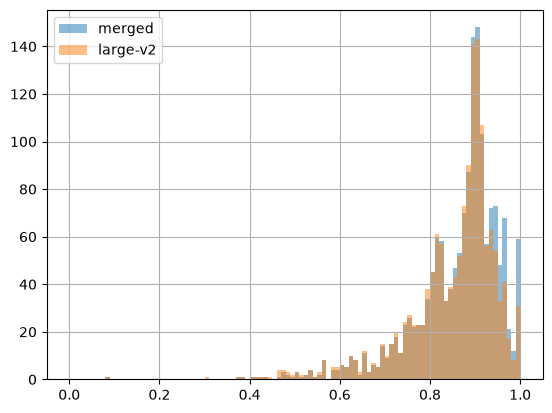

In [51]:
merged.confidence.hist(bins=np.arange(0, 1.01, 0.01), alpha=0.5, label='merged')
df_whisper.confidence.hist(bins=np.arange(0, 1.01, 0.01), alpha=0.5, label='large-v2')
plt.legend()
plt.show()